In [ ]:
import numpy as np

export_path = "/nfs/home/victor.franco/moment_input.npz"  # ou o caminho completo

data = np.load(export_path, allow_pickle=True)

X = data["X"]                       # (n_janelas, window_size, n_variaveis)
file_name = data["file_name"]       # (n_janelas,)
relative_path = data["relative_path"]
window_idx = data["window_idx"]
signal_columns = data["signal_columns"]

print("X shape:", X.shape)
print("n variáveis:", len(signal_columns))
print("primeiras variáveis:", signal_columns[:5])
print("primeira janela veio de:", relative_path[0], "arquivo:", file_name[0], "window:", window_idx[0])


X shape: (205040, 128, 14)
n variáveis: 14
primeiras variáveis: ['ESTADO-DHSV' 'ESTADO-M1' 'ESTADO-M2' 'ESTADO-PXO' 'ESTADO-SDV-GL']
primeira janela veio de: 1/DRAWN_00001.parquet arquivo: 1/DRAWN_00001.parquet window: 0


In [2]:
import numpy as np

import torch
import torch.cuda.amp as amp
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import OneCycleLR
from tqdm import tqdm

from momentfm import MOMENTPipeline
from momentfm.utils.utils import control_randomness

# =========================================================
# Configurações
# =========================================================
SEED = 13
BATCH_SIZE = 32
MAX_EPOCHS = 10
LR = 1e-4
MAX_NORM = 5.0
TRAIN_RATIO = 0.8

N_CHANNELS = 14

WINDOW = 128
PAST_LEN = 64
FUTURE_LEN = 64
assert PAST_LEN + FUTURE_LEN == WINDOW, "PAST_LEN + FUTURE_LEN deve ser igual a WINDOW"

FORECAST_HORIZON = FUTURE_LEN  # agora prevemos 64 pontos

# Sensores de baixa cardinalidade
LOW_CARD_SENSORS = [0, 1, 2, 3, 4, 5, 6, 7, 8]
CONT_SENSORS = [i for i in range(N_CHANNELS) if i not in LOW_CARD_SENSORS]

# Pesos da loss
LOW_CARD_WEIGHT = 1.0
CONT_WEIGHT = 1.0

control_randomness(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# =========================================================
# Checagens de entrada
# =========================================================
assert isinstance(X, np.ndarray), "X precisa ser numpy.ndarray"
assert X.ndim == 3, f"Esperado X com 3 dimensões (N, T, C), mas veio {X.shape}"
assert X.shape[1] == WINDOW, f"Esperado janela {WINDOW}, mas veio {X.shape[1]}"
assert X.shape[2] == N_CHANNELS, f"Esperado {N_CHANNELS} canais, mas veio {X.shape[2]}"

X = X.astype(np.float32)

# =========================================================
# Split treino/teste
# =========================================================
n_samples = X.shape[0]
train_end = int(n_samples * TRAIN_RATIO)

X_train_raw = X[:train_end]
X_test_raw = X[train_end:]

# =========================================================
# Pré-processamento
# - sensores LOW_CARD ficam sem normalização
# - sensores contínuos são normalizados
# =========================================================
X_proc = X.copy()

mean_cont = X_train_raw[:, :, CONT_SENSORS].mean(axis=(0, 1), keepdims=True)
std_cont = X_train_raw[:, :, CONT_SENSORS].std(axis=(0, 1), keepdims=True)
std_cont = np.where(std_cont < 1e-8, 1.0, std_cont)

X_proc[:, :, CONT_SENSORS] = (X_proc[:, :, CONT_SENSORS] - mean_cont) / std_cont

train_mean_full = np.zeros((1, 1, N_CHANNELS), dtype=np.float32)
train_std_full = np.ones((1, 1, N_CHANNELS), dtype=np.float32)

train_mean_full[:, :, CONT_SENSORS] = mean_cont
train_std_full[:, :, CONT_SENSORS] = std_cont

# =========================================================
# Dataset
# Usa dentro da mesma janela:
# past = primeiros 64 pontos
# future = últimos 64 pontos
# =========================================================
class WindowToFutureWithinWindowForecastDataset(Dataset):
    def __init__(self, X, past_len=64, future_len=64):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.past_len = past_len
        self.future_len = future_len

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        w = self.X[idx]  # (128, C)
        past = w[: self.past_len]  # (64, C)
        future = w[self.past_len : self.past_len + self.future_len]  # (64, C)
        input_mask = torch.ones(past.shape[0], dtype=torch.long)  # (64,)
        return past, future, input_mask

train_dataset = WindowToFutureWithinWindowForecastDataset(
    X_proc[:train_end], past_len=PAST_LEN, future_len=FUTURE_LEN
)
test_dataset = WindowToFutureWithinWindowForecastDataset(
    X_proc[train_end:], past_len=PAST_LEN, future_len=FUTURE_LEN
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    num_workers=4,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=4,
)

print("train samples:", len(train_dataset))
print("test samples:", len(test_dataset))
print("low-card sensors:", LOW_CARD_SENSORS)
print("continuous sensors:", CONT_SENSORS)

# =========================================================
# Modelo
# =========================================================
model = MOMENTPipeline.from_pretrained(
    "AutonLab/MOMENT-1-small",
    model_kwargs={
        "task_name": "forecasting",
        "forecast_horizon": FORECAST_HORIZON,  # 64
        "head_dropout": 0.1,
        "n_channels": N_CHANNELS,
        "weight_decay": 0,
        "freeze_encoder": True,
        "freeze_embedder": True,
        "freeze_head": False,
    },
)
model = model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)

total_steps = len(train_loader) * MAX_EPOCHS
scheduler = OneCycleLR(
    optimizer,
    max_lr=LR,
    total_steps=total_steps,
    pct_start=0.3,
)

scaler = amp.GradScaler()

# =========================================================
# Funções auxiliares
# =========================================================
def get_forecast_prediction(model, timeseries, input_mask):
    """
    timeseries: tensor (B, C, T)
    input_mask: tensor (B, T)
    """
    pred = None

    if hasattr(model, "forecast") and callable(getattr(model, "forecast")):
        out = model.forecast(x_enc=timeseries, input_mask=input_mask)

        if isinstance(out, torch.Tensor):
            pred = out
        elif hasattr(out, "forecast") and out.forecast is not None:
            pred = out.forecast
        elif hasattr(out, "logits") and out.logits is not None:
            pred = out.logits
        elif hasattr(out, "reconstruction") and out.reconstruction is not None:
            pred = out.reconstruction

    if pred is None:
        out = model(x_enc=timeseries, input_mask=input_mask)

        if hasattr(out, "forecast") and out.forecast is not None:
            pred = out.forecast
        elif hasattr(out, "logits") and out.logits is not None:
            pred = out.logits

    if pred is None:
        raise ValueError(
            "Não foi possível obter previsão do modelo. "
            "Verifique o retorno de model.forecast ou model(...)."
        )

    return pred


def ensure_bct(tensor):
    """
    Converte para (B, C, T), se vier em (B, T, C).
    Aqui T deve ser FORECAST_HORIZON (=64).
    """
    if tensor.ndim != 3:
        raise ValueError(f"Tensor com ndim inesperado: {tensor.ndim}, shape={tensor.shape}")

    if tensor.shape[1] == N_CHANNELS and tensor.shape[2] == FORECAST_HORIZON:
        return tensor  # já está em BCT
    elif tensor.shape[1] == FORECAST_HORIZON and tensor.shape[2] == N_CHANNELS:
        return tensor.permute(0, 2, 1)  # BTC -> BCT
    else:
        raise ValueError(
            f"Shape inesperado: {tensor.shape}. "
            f"Esperado (B,{N_CHANNELS},{FORECAST_HORIZON}) ou (B,{FORECAST_HORIZON},{N_CHANNELS})."
        )


def mixed_forecast_loss(pred_bct, target_bct):
    """
    pred_bct: (B, C, T=64)
    target_bct: (B, C, T=64)
    """
    pred_low = pred_bct[:, LOW_CARD_SENSORS, :]
    target_low = target_bct[:, LOW_CARD_SENSORS, :]

    pred_cont = pred_bct[:, CONT_SENSORS, :]
    target_cont = target_bct[:, CONT_SENSORS, :]

    pred_low_prob = torch.sigmoid(pred_low)
    loss_low = torch.mean((pred_low_prob - target_low) ** 2)

    loss_cont = torch.mean((pred_cont - target_cont) ** 2)

    total_loss = LOW_CARD_WEIGHT * loss_low + CONT_WEIGHT * loss_cont
    return total_loss, loss_low.detach(), loss_cont.detach()


def postprocess_prediction_for_metrics(pred_bct):
    pred_out = pred_bct.clone()
    pred_out[:, LOW_CARD_SENSORS, :] = torch.sigmoid(pred_out[:, LOW_CARD_SENSORS, :])
    return pred_out


def compute_metrics(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    mae = np.mean(np.abs(y_true - y_pred))
    return mse, mae


def denormalize_processed_data(x_btc):
    """
    x_btc: numpy array (B, T, C) no espaço processado
    Retorna no espaço original.
    """
    x_denorm = x_btc.copy()
    x_denorm[:, :, CONT_SENSORS] = (
        x_denorm[:, :, CONT_SENSORS] * train_std_full[:, :, CONT_SENSORS]
        + train_mean_full[:, :, CONT_SENSORS]
    )
    return x_denorm

# =========================================================
# Diagnóstico rápido antes do treino
# =========================================================
timeseries_dbg, forecast_dbg, input_mask_dbg = next(iter(train_loader))
timeseries_dbg = timeseries_dbg.float().to(device).permute(0, 2, 1)  # (B, C, 64)
forecast_dbg = forecast_dbg.float().to(device)  # (B, 64, C)
input_mask_dbg = input_mask_dbg.to(device)  # (B, 64)

with torch.no_grad():
    pred_dbg = get_forecast_prediction(model, timeseries_dbg, input_mask_dbg)

pred_dbg_bct = ensure_bct(pred_dbg)
target_dbg_bct = ensure_bct(forecast_dbg)

print("DEBUG input shape:", tuple(timeseries_dbg.shape))
print("DEBUG pred raw shape:", tuple(pred_dbg.shape))
print("DEBUG pred BCT shape:", tuple(pred_dbg_bct.shape))
print("DEBUG target BCT shape:", tuple(target_dbg_bct.shape))

# =========================================================
# Treino e avaliação
# =========================================================
for epoch in range(MAX_EPOCHS):
    model.train()
    train_losses = []
    train_low_losses = []
    train_cont_losses = []

    for timeseries, forecast, input_mask in tqdm(train_loader, desc=f"Train {epoch+1}/{MAX_EPOCHS}"):
        timeseries = timeseries.float().to(device)  # (B, 64, C)
        forecast = forecast.float().to(device)      # (B, 64, C)
        input_mask = input_mask.to(device)          # (B, 64)

        timeseries_bct = timeseries.permute(0, 2, 1)  # (B, C, 64)
        target_bct = ensure_bct(forecast)             # (B, C, 64)

        optimizer.zero_grad(set_to_none=True)

        with amp.autocast():
            pred = get_forecast_prediction(model, timeseries_bct, input_mask)
            pred_bct = ensure_bct(pred)

            if pred_bct.shape != target_bct.shape:
                raise ValueError(
                    f"Shapes incompatíveis no treino: pred={pred_bct.shape}, target={target_bct.shape}"
                )

            loss, loss_low, loss_cont = mixed_forecast_loss(pred_bct, target_bct)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_NORM)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        train_losses.append(loss.item())
        train_low_losses.append(loss_low.item())
        train_cont_losses.append(loss_cont.item())

    avg_train_loss = float(np.mean(train_losses))
    avg_train_low = float(np.mean(train_low_losses))
    avg_train_cont = float(np.mean(train_cont_losses))

    # =====================================================
    # Avaliação
    # =====================================================
    model.eval()
    test_losses = []
    test_low_losses = []
    test_cont_losses = []
    trues = []
    preds = []

    with torch.no_grad():
        for timeseries, forecast, input_mask in tqdm(test_loader, desc=f"Test {epoch+1}/{MAX_EPOCHS}"):
            timeseries = timeseries.float().to(device)  # (B, 64, C)
            forecast = forecast.float().to(device)      # (B, 64, C)
            input_mask = input_mask.to(device)          # (B, 64)

            timeseries_bct = timeseries.permute(0, 2, 1)  # (B, C, 64)
            target_bct = ensure_bct(forecast)             # (B, C, 64)

            with amp.autocast():
                pred = get_forecast_prediction(model, timeseries_bct, input_mask)
                pred_bct = ensure_bct(pred)

                if pred_bct.shape != target_bct.shape:
                    raise ValueError(
                        f"Shapes incompatíveis na avaliação: pred={pred_bct.shape}, target={target_bct.shape}"
                    )

                loss, loss_low, loss_cont = mixed_forecast_loss(pred_bct, target_bct)

            pred_post_bct = postprocess_prediction_for_metrics(pred_bct)

            test_losses.append(loss.item())
            test_low_losses.append(loss_low.item())
            test_cont_losses.append(loss_cont.item())

            trues.append(target_bct.detach().cpu().numpy())
            preds.append(pred_post_bct.detach().cpu().numpy())

    avg_test_loss = float(np.mean(test_losses))
    avg_test_low = float(np.mean(test_low_losses))
    avg_test_cont = float(np.mean(test_cont_losses))

    trues = np.concatenate(trues, axis=0)  # (N, C, 64)
    preds = np.concatenate(preds, axis=0)  # (N, C, 64)

    mse, mae = compute_metrics(trues, preds)

    print(
        f"Epoch {epoch+1}/{MAX_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Train Low: {avg_train_low:.6f} | "
        f"Train Cont: {avg_train_cont:.6f} | "
        f"Test Loss: {avg_test_loss:.6f} | "
        f"Test Low: {avg_test_low:.6f} | "
        f"Test Cont: {avg_test_cont:.6f} | "
        f"Test MSE: {mse:.6f} | "
        f"Test MAE: {mae:.6f}"
    )


device: cuda


train samples: 164032
test samples: 41008
low-card sensors: [0, 1, 2, 3, 4, 5, 6, 7, 8]
continuous sensors: [9, 10, 11, 12, 13]


/tmp/ipykernel_600123/2976816823.py:159: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


DEBUG input shape: (32, 14, 64)
DEBUG pred raw shape: (32, 14, 64)
DEBUG pred BCT shape: (32, 14, 64)
DEBUG target BCT shape: (32, 14, 64)


Train 1/10:   0%|          | 0/5126 [00:00<?, ?it/s]/tmp/ipykernel_600123/2976816823.py:301: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():
Test 1/10:   0%|          | 0/1282 [00:00<?, ?it/s]/tmp/ipykernel_600123/2976816823.py:346: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():
Test 1/10: 100%|██████████| 1282/1282 [00:15<00:00, 83.77it/s]


...

Epoch 8/10 | Train Loss: 0.113548 | Train Low: 0.111617 | Train Cont: 0.001931 | Test Loss: 0.129274 | Test Low: 0.128676 | Test Cont: 0.000598 | Test MSE: 0.082940 | Test MAE: 0.199687


Test 9/10: 100%|██████████| 1282/1282 [00:18<00:00, 71.05it/s]


Epoch 9/10 | Train Loss: 0.113543 | Train Low: 0.111617 | Train Cont: 0.001926 | Test Loss: 0.129274 | Test Low: 0.128676 | Test Cont: 0.000598 | Test MSE: 0.082940 | Test MAE: 0.199687


Test 10/10: 100%|██████████| 1282/1282 [00:16<00:00, 79.78it/s]


Epoch 10/10 | Train Loss: 0.113547 | Train Low: 0.111617 | Train Cont: 0.001930 | Test Loss: 0.129274 | Test Low: 0.128676 | Test Cont: 0.000598 | Test MSE: 0.082940 | Test MAE: 0.199687


dataset_idx selecionado: 178352


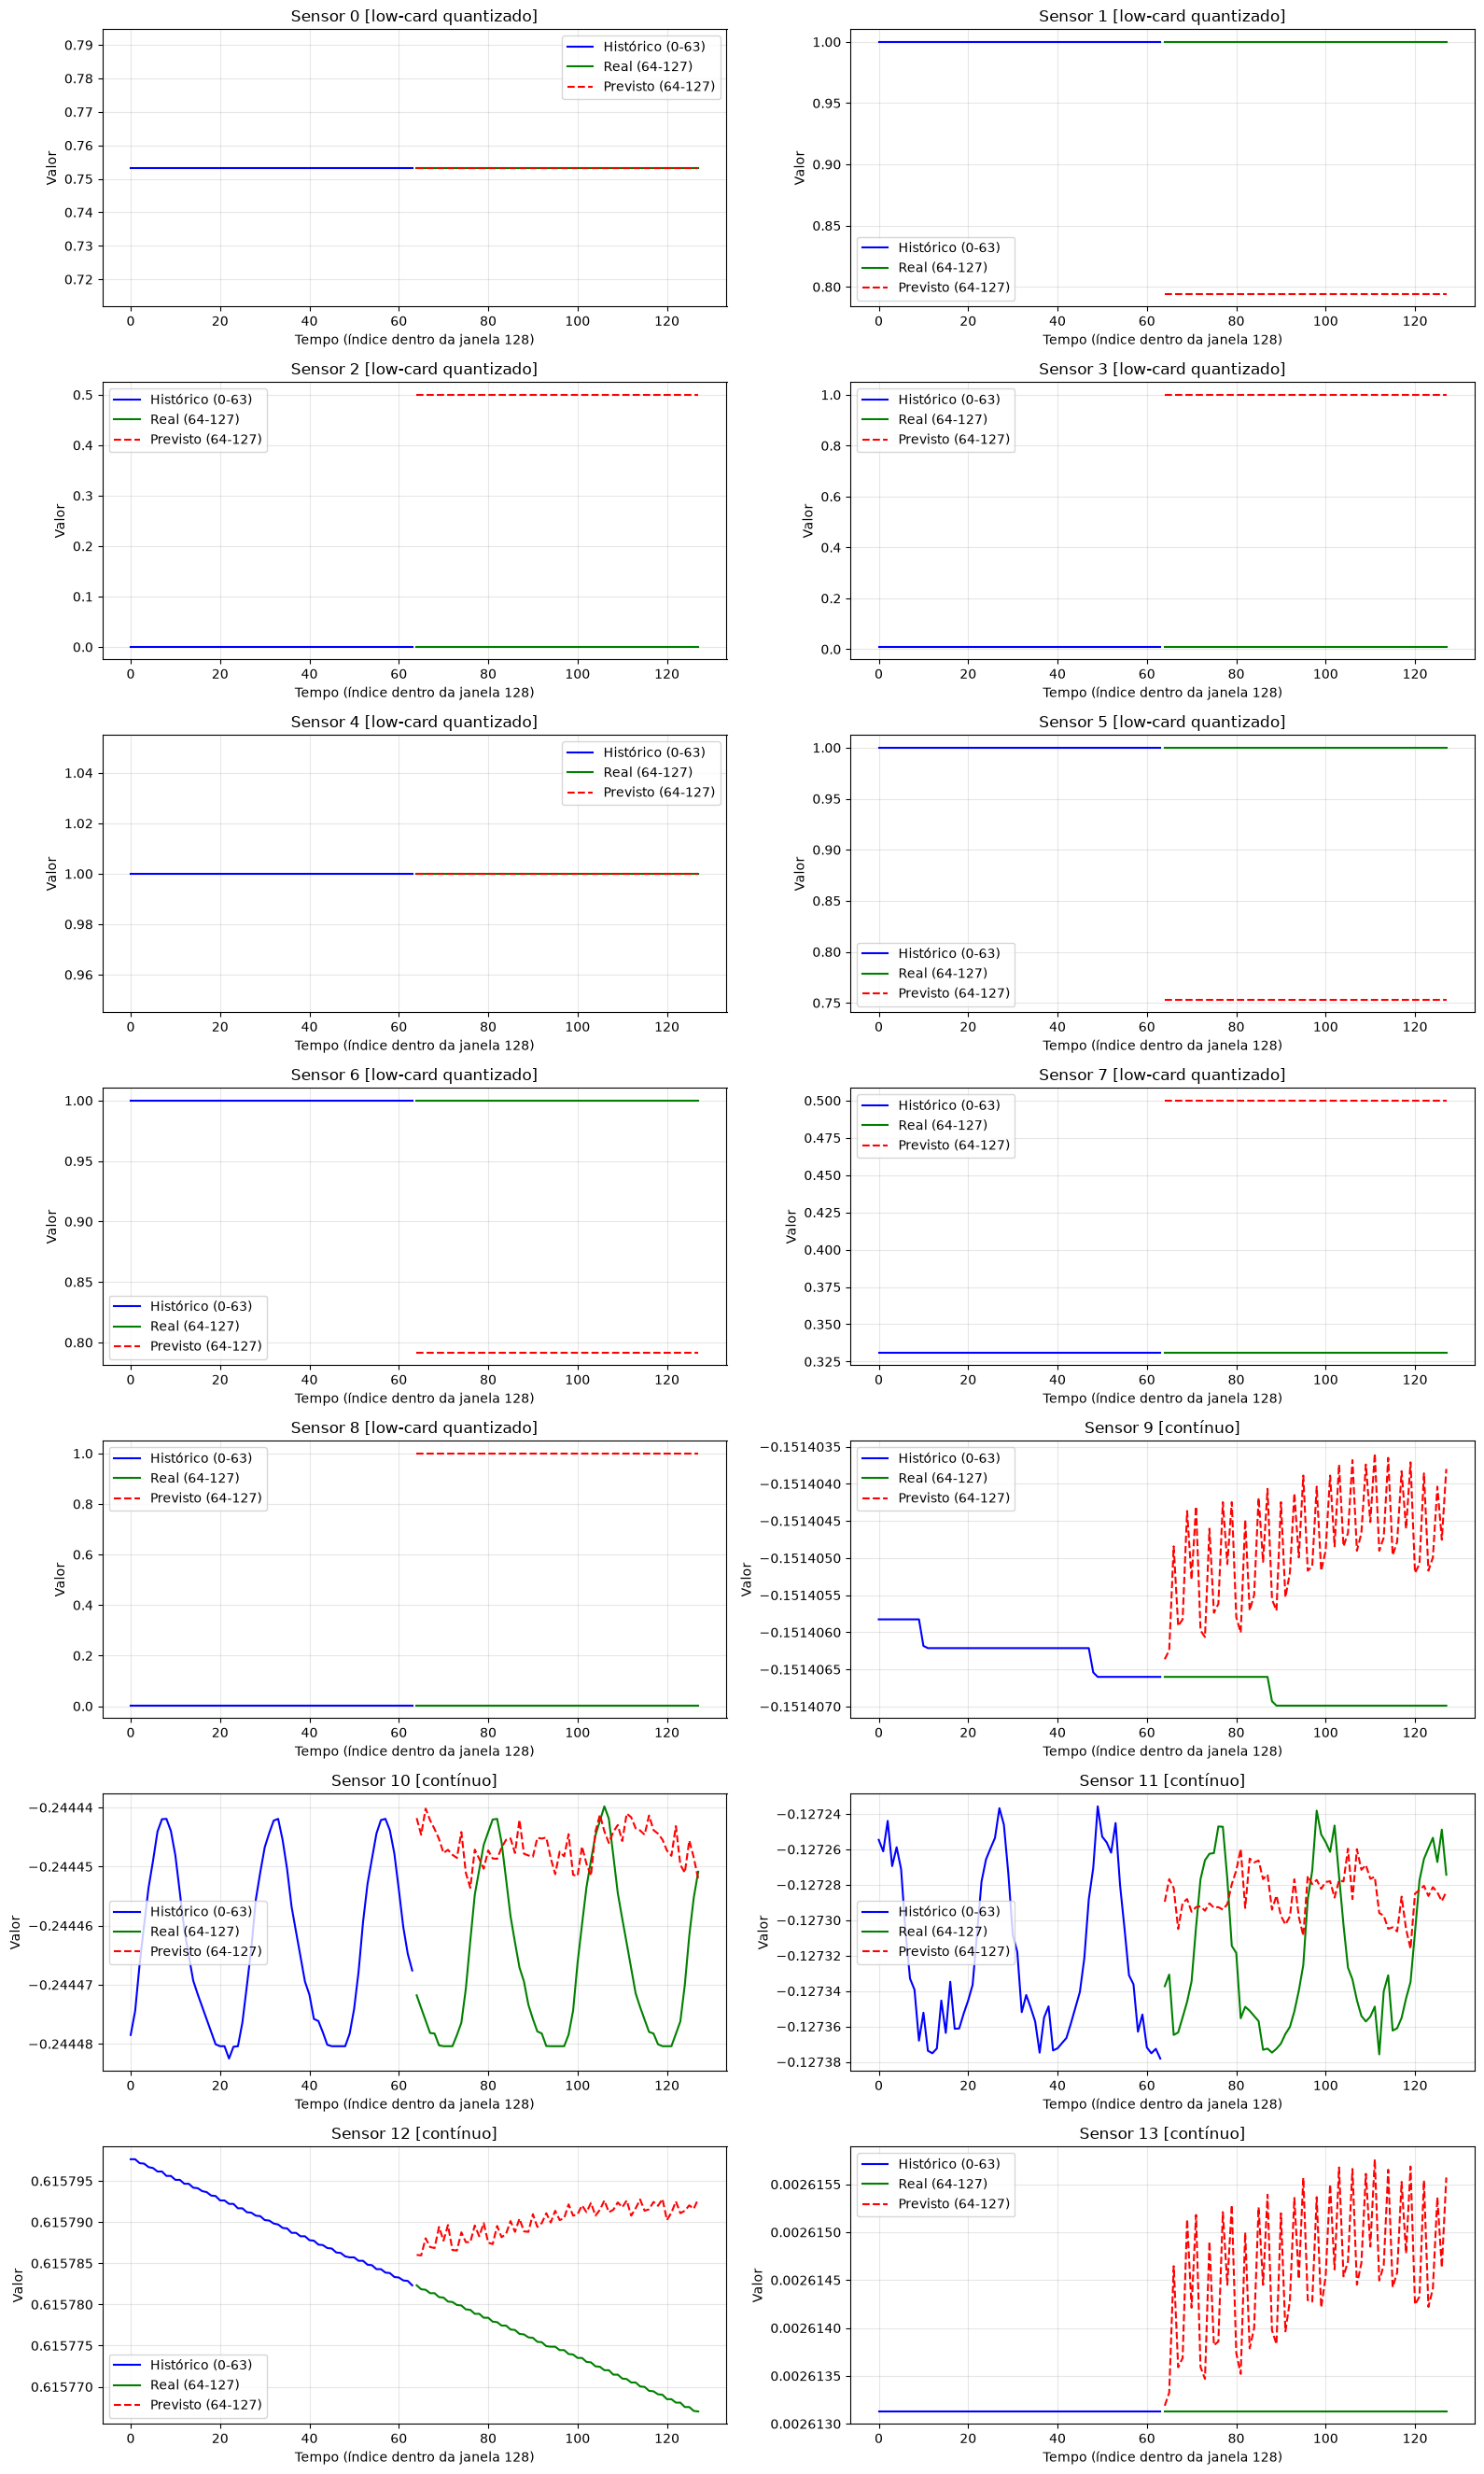

In [3]:
# =========================================================
# Análise/Plot adaptado para lógica 64->64 (dentro da mesma janela de 128)
# - histórico = primeiros 64 pontos
# - futuro real = últimos 64 pontos
# - futuro previsto = previsão para esses 64 pontos
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch

# ---------------------------------------------------------
# Assume que estas variáveis já existem do seu treino:
# device, model, N_CHANNELS, LOW_CARD_SENSORS, CONT_SENSORS,
# train_mean_full, train_std_full, get_forecast_prediction, ensure_bct
# e que WINDOW=128, PAST_LEN=64, FUTURE_LEN=64, FORECAST_HORIZON=64
# ---------------------------------------------------------

WINDOW = 128
PAST_LEN = 64
FUTURE_LEN = 64
FORECAST_HORIZON = FUTURE_LEN

# =========================================================
# Dataset 64->64 (mesma janela)
# =========================================================
class WindowToFutureWithinWindowForecastDataset(torch.utils.data.Dataset):
    def __init__(self, X, past_len=64, future_len=64):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.past_len = past_len
        self.future_len = future_len

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        w = self.X[idx]  # (128, C)
        past = w[: self.past_len]  # (64, C)
        future = w[self.past_len : self.past_len + self.future_len]  # (64, C)
        input_mask = torch.ones(past.shape[0], dtype=torch.long)  # (64,)
        return past, future, input_mask

# =========================================================
# Carrega datasets (anomalia, normal, transiente)
# =========================================================
export_path = "/nfs/home/victor.franco/moment_input_anomalia.npz"
data = np.load(export_path, allow_pickle=True)
X_anomalia = data["X"].astype(np.float32)
test_dataset_anomalia = WindowToFutureWithinWindowForecastDataset(X_anomalia, past_len=PAST_LEN, future_len=FUTURE_LEN)

export_path = "/nfs/home/victor.franco/moment_input_normal.npz"
data = np.load(export_path, allow_pickle=True)
X_normal = data["X"].astype(np.float32)
test_dataset_normal = WindowToFutureWithinWindowForecastDataset(X_normal, past_len=PAST_LEN, future_len=FUTURE_LEN)

export_path = "/nfs/home/victor.franco/moment_input_transiente.npz"
data = np.load(export_path, allow_pickle=True)
X_transiente = data["X"].astype(np.float32)
test_dataset_transiente = WindowToFutureWithinWindowForecastDataset(X_transiente, past_len=PAST_LEN, future_len=FUTURE_LEN)

# =========================================================
# Configurações de plot
# =========================================================
sensors_to_plot = list(range(N_CHANNELS))
sensor_names = [f"Sensor {i}" for i in range(N_CHANNELS)]

LOW_CARD_ALLOWED_VALUES = {
    0: np.array([0.0, 0.7532467, 1.0], dtype=np.float32),
    1: np.array([0.0, 0.79411507, 1.0], dtype=np.float32),
    2: np.array([0.0, 0.39249185, 0.5, 1.0], dtype=np.float32),
    3: np.array([0.0, 0.00872915, 1.0], dtype=np.float32),
    4: np.array([0.0, 0.35660064, 1.0], dtype=np.float32),
    5: np.array([0.0, 0.752948, 1.0], dtype=np.float32),
    6: np.array([0.0, 0.7914691, 1.0], dtype=np.float32),
    7: np.array([0.0, 0.3309143, 0.5, 1.0], dtype=np.float32),
    8: np.array([0.0, 0.00195548, 1.0], dtype=np.float32),
}

# =========================================================
# Funções auxiliares (numpy)
# =========================================================
def bct_to_btc(x):
    return np.transpose(x, (0, 2, 1))

def postprocess_low_card_numpy(x_btc):
    x_out = x_btc.copy()
    x_out[:, :, LOW_CARD_SENSORS] = 1.0 / (1.0 + np.exp(-x_out[:, :, LOW_CARD_SENSORS]))
    return x_out

def quantize_low_card_predictions(x_btc):
    x_out = x_btc.copy()
    for sensor_idx, allowed in LOW_CARD_ALLOWED_VALUES.items():
        vals = x_out[:, :, sensor_idx]  # (B, T)
        dists = np.abs(vals[:, :, None] - allowed[None, None, :])  # (B, T, K)
        nearest = np.argmin(dists, axis=2)
        x_out[:, :, sensor_idx] = allowed[nearest]
    return x_out

def denormalize_continuous_only(x_btc):
    x_out = x_btc.copy()
    x_out[:, :, CONT_SENSORS] = (
        x_out[:, :, CONT_SENSORS] * train_std_full[:, :, CONT_SENSORS]
        + train_mean_full[:, :, CONT_SENSORS]
    )
    return x_out

# =========================================================
# Escolha qual dataset analisar
# =========================================================
test_dataset = test_dataset_anomalia   # <- troque para test_dataset_normal ou test_dataset_transiente se quiser

dataset_idx = np.random.randint(0, len(test_dataset))
print("dataset_idx selecionado:", dataset_idx)

# =========================================================
# Pega uma amostra do dataset
# =========================================================
timeseries, forecast, input_mask = test_dataset[dataset_idx]

# adiciona dimensão de batch
timeseries = timeseries.unsqueeze(0).float().to(device)    # (1, 64, C)
forecast   = forecast.unsqueeze(0).float().to(device)      # (1, 64, C)
input_mask = input_mask.unsqueeze(0).to(device)            # (1, 64)

timeseries_bct = timeseries.permute(0, 2, 1)               # (1, C, 64)

# =========================================================
# Previsão
# =========================================================
model.eval()
with torch.no_grad():
    pred = get_forecast_prediction(model, timeseries_bct, input_mask)
    pred_bct = ensure_bct(pred)                            # (1, C, 64)

history_btc = timeseries.detach().cpu().numpy()            # (1, 64, C)
target_btc  = forecast.detach().cpu().numpy()              # (1, 64, C)
pred_btc    = bct_to_btc(pred_bct.detach().cpu().numpy())  # (1, 64, C)

# =========================================================
# Pós-processamento
# =========================================================
pred_btc   = postprocess_low_card_numpy(pred_btc)
pred_btc   = quantize_low_card_predictions(pred_btc)
target_btc = quantize_low_card_predictions(target_btc)
history_btc= quantize_low_card_predictions(history_btc)

# desnormaliza apenas sensores contínuos
history_btc = denormalize_continuous_only(history_btc)
target_btc  = denormalize_continuous_only(target_btc)
pred_btc    = denormalize_continuous_only(pred_btc)

# =========================================================
# Seleciona a amostra do batch
# =========================================================
history_sample = history_btc[0]   # (64, C)
target_sample  = target_btc[0]    # (64, C)
pred_sample    = pred_btc[0]      # (64, C)

# =========================================================
# Plot (histórico em [0..63], futuro em [64..127])
# =========================================================
n_plots = len(sensors_to_plot)
n_cols = 2
n_rows = int(np.ceil(n_plots / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.8 * n_rows), sharex=False)
axes = np.array(axes).reshape(-1)

x_hist = np.arange(0, PAST_LEN)                         # 0..63
x_future = np.arange(PAST_LEN, PAST_LEN + FUTURE_LEN)   # 64..127

for plot_idx, sensor_idx in enumerate(sensors_to_plot):
    ax = axes[plot_idx]

    ax.plot(x_hist, history_sample[:, sensor_idx], label="Histórico (0-63)", color="blue", linewidth=1.5)
    ax.plot(x_future, target_sample[:, sensor_idx], label="Real (64-127)", color="green", linewidth=1.5)
    ax.plot(x_future, pred_sample[:, sensor_idx], label="Previsto (64-127)", color="red", linestyle="--", linewidth=1.5)

    title = sensor_names[sensor_idx]
    if sensor_idx in LOW_CARD_SENSORS:
        title += " [low-card quantizado]"
    else:
        title += " [contínuo]"

    ax.set_title(title)
    ax.set_xlabel("Tempo (índice dentro da janela 128)")
    ax.set_ylabel("Valor")
    ax.ticklabel_format(style="plain", axis="y", useOffset=False)
    ax.grid(True, alpha=0.3)
    ax.legend()

for i in range(n_plots, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()


preds shape: (227860, 14, 64)
trues shape: (227860, 14, 64)


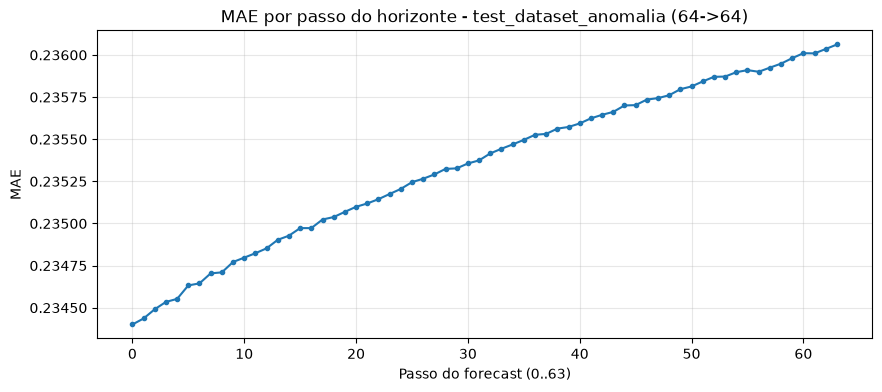

MAE passo 0 : 0.23440064
MAE passo 1 : 0.23443629
MAE passo 2 : 0.23449112
MAE médio : 0.23534751


In [4]:
# =========================================================
# Avaliação em lote (DataLoader) adaptada para lógica 64->64
# Saída final em (N, C, T) com T=64
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# ---------------------------------------------------------
# Assume que já existem (do treino):
# device, model, BATCH_SIZE, N_CHANNELS, LOW_CARD_SENSORS,
# get_forecast_prediction, ensure_bct,
# postprocess_low_card_numpy, quantize_low_card_predictions
# e que o dataset já é o de 64->64: test_dataset_anomalia
# ---------------------------------------------------------

PAST_LEN = 64
FUTURE_LEN = 64
FORECAST_HORIZON = FUTURE_LEN  # 64

# =========================================================
# DataLoader para o dataset de anomalia (64->64)
# =========================================================
test_loader_anomalia = DataLoader(
    test_dataset_anomalia,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=4,
)

# =========================================================
# Geração de preds e trues
# Saída final em (N, C, T=64)
# =========================================================
model.eval()

trues = []
preds = []

with torch.no_grad():
    for timeseries, forecast, input_mask in test_loader_anomalia:
        timeseries = timeseries.float().to(device)  # (B, 64, C)
        forecast = forecast.float().to(device)      # (B, 64, C)
        input_mask = input_mask.to(device)          # (B, 64)

        timeseries_bct = timeseries.permute(0, 2, 1)  # (B, C, 64)
        target_bct = ensure_bct(forecast)             # (B, C, 64)

        pred = get_forecast_prediction(model, timeseries_bct, input_mask)
        pred_bct = ensure_bct(pred)                   # (B, C, 64)

        # pós-processamento igual ao usado antes (mas agora T=64)
        pred_btc = np.transpose(pred_bct.detach().cpu().numpy(), (0, 2, 1))    # (B, 64, C)
        target_btc = np.transpose(target_bct.detach().cpu().numpy(), (0, 2, 1))# (B, 64, C)

        pred_btc = postprocess_low_card_numpy(pred_btc)
        pred_btc = quantize_low_card_predictions(pred_btc)

        # (opcional, mas consistente com sua lógica anterior)
        target_btc = quantize_low_card_predictions(target_btc)

        # volta para (B, C, 64)
        pred_bct_np = np.transpose(pred_btc, (0, 2, 1))
        target_bct_np = np.transpose(target_btc, (0, 2, 1))

        preds.append(pred_bct_np)
        trues.append(target_bct_np)

preds = np.concatenate(preds, axis=0)  # (N, C, 64)
trues = np.concatenate(trues, axis=0)  # (N, C, 64)

print("preds shape:", preds.shape)
print("trues shape:", trues.shape)

# =========================================================
# MAE por passo do horizonte (T=64)
# =========================================================
abs_err = np.abs(preds - trues)
mae_por_passo = abs_err.mean(axis=(0, 1))  # (64,)

plt.figure(figsize=(10, 4))
plt.plot(mae_por_passo, marker="o", markersize=3)
plt.title("MAE por passo do horizonte - test_dataset_anomalia (64->64)")
plt.xlabel("Passo do forecast (0..63)")
plt.ylabel("MAE")
plt.grid(True, alpha=0.3)
plt.show()

print("MAE passo 0 :", mae_por_passo[0])
print("MAE passo 1 :", mae_por_passo[1])
print("MAE passo 2 :", mae_por_passo[2])
print("MAE médio :", mae_por_passo.mean())


In [5]:
import numpy as np
from pathlib import Path
EXPORT_PATH = Path("./resultado_anomalia.npz")

# preds: (N, C, 64)
# trues: (N, C, 64)

np.savez_compressed(
    EXPORT_PATH,
    y_pred=preds.astype(np.float32),
    y_true=trues.astype(np.float32)
)


print("Salvo em:", EXPORT_PATH)


Salvo em: resultado_anomalia.npz


preds shape: (135976, 14, 64)
trues shape: (135976, 14, 64)


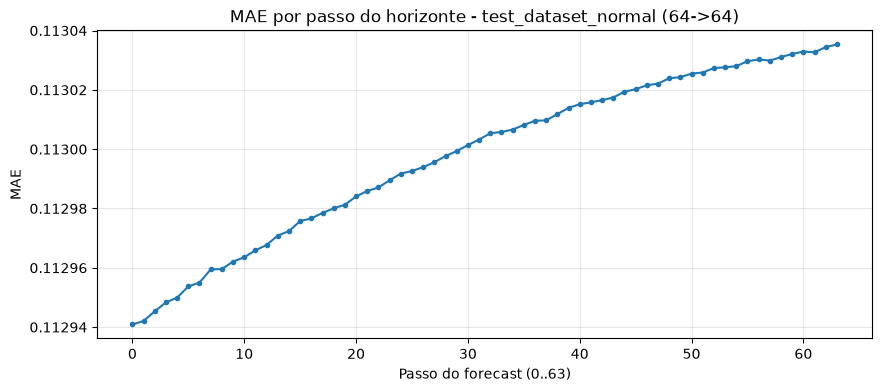

MAE passo 0 : 0.11294088
MAE passo 1 : 0.11294207
MAE passo 2 : 0.112945326
MAE médio : 0.11299783


In [6]:
# =========================================================
# Avaliação em lote (DataLoader) adaptada para lógica 64->64
# Saída final em (N, C, T) com T=64
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# ---------------------------------------------------------
# Assume que já existem (do treino):
# device, model, BATCH_SIZE, N_CHANNELS, LOW_CARD_SENSORS,
# get_forecast_prediction, ensure_bct,
# postprocess_low_card_numpy, quantize_low_card_predictions
# e que o dataset já é o de 64->64: test_dataset_anomalia
# ---------------------------------------------------------

PAST_LEN = 64
FUTURE_LEN = 64
FORECAST_HORIZON = FUTURE_LEN  # 64

# =========================================================
# DataLoader para o dataset de anomalia (64->64)
# =========================================================
test_loader_anomalia = DataLoader(
    test_dataset_normal,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=4,
)

# =========================================================
# Geração de preds e trues
# Saída final em (N, C, T=64)
# =========================================================
model.eval()

trues = []
preds = []

with torch.no_grad():
    for timeseries, forecast, input_mask in test_loader_anomalia:
        timeseries = timeseries.float().to(device)  # (B, 64, C)
        forecast = forecast.float().to(device)      # (B, 64, C)
        input_mask = input_mask.to(device)          # (B, 64)

        timeseries_bct = timeseries.permute(0, 2, 1)  # (B, C, 64)
        target_bct = ensure_bct(forecast)             # (B, C, 64)

        pred = get_forecast_prediction(model, timeseries_bct, input_mask)
        pred_bct = ensure_bct(pred)                   # (B, C, 64)

        # pós-processamento igual ao usado antes (mas agora T=64)
        pred_btc = np.transpose(pred_bct.detach().cpu().numpy(), (0, 2, 1))    # (B, 64, C)
        target_btc = np.transpose(target_bct.detach().cpu().numpy(), (0, 2, 1))# (B, 64, C)

        pred_btc = postprocess_low_card_numpy(pred_btc)
        pred_btc = quantize_low_card_predictions(pred_btc)

        # (opcional, mas consistente com sua lógica anterior)
        target_btc = quantize_low_card_predictions(target_btc)

        # volta para (B, C, 64)
        pred_bct_np = np.transpose(pred_btc, (0, 2, 1))
        target_bct_np = np.transpose(target_btc, (0, 2, 1))

        preds.append(pred_bct_np)
        trues.append(target_bct_np)

preds = np.concatenate(preds, axis=0)  # (N, C, 64)
trues = np.concatenate(trues, axis=0)  # (N, C, 64)

print("preds shape:", preds.shape)
print("trues shape:", trues.shape)

# =========================================================
# MAE por passo do horizonte (T=64)
# =========================================================
abs_err = np.abs(preds - trues)
mae_por_passo = abs_err.mean(axis=(0, 1))  # (64,)

plt.figure(figsize=(10, 4))
plt.plot(mae_por_passo, marker="o", markersize=3)
plt.title("MAE por passo do horizonte - test_dataset_normal (64->64)")
plt.xlabel("Passo do forecast (0..63)")
plt.ylabel("MAE")
plt.grid(True, alpha=0.3)
ax = plt.gca()
ax.ticklabel_format(axis='y', style='plain', useOffset=False)
plt.show()

print("MAE passo 0 :", mae_por_passo[0])
print("MAE passo 1 :", mae_por_passo[1])
print("MAE passo 2 :", mae_por_passo[2])
print("MAE médio :", mae_por_passo.mean())


In [7]:
import numpy as np
from pathlib import Path
EXPORT_PATH = Path("./resultado_normal.npz")

# preds: (N, C, 64)
# trues: (N, C, 64)

np.savez_compressed(
    EXPORT_PATH,
    y_pred=preds.astype(np.float32),
    y_true=trues.astype(np.float32)
)


print("Salvo em:", EXPORT_PATH)


Salvo em: resultado_normal.npz


preds shape: (205040, 14, 64)
trues shape: (205040, 14, 64)


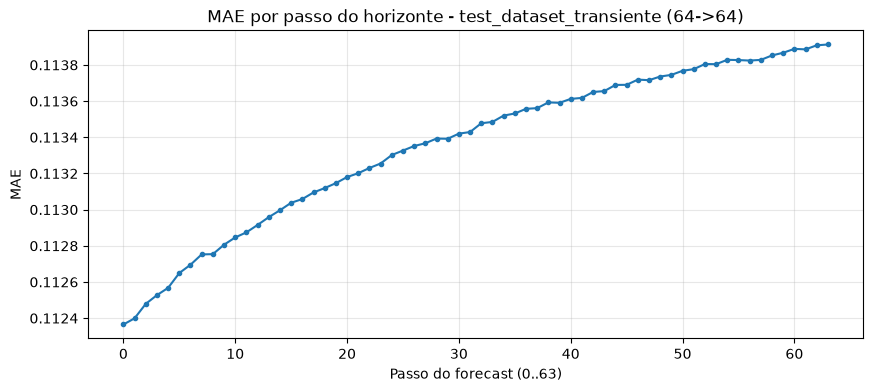

MAE passo 0 : 0.11236493
MAE passo 1 : 0.11239916
MAE passo 2 : 0.112479046
MAE médio : 0.113356486


In [8]:
# =========================================================
# Avaliação em lote (DataLoader) adaptada para lógica 64->64
# Saída final em (N, C, T) com T=64
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# ---------------------------------------------------------
# Assume que já existem (do treino):
# device, model, BATCH_SIZE, N_CHANNELS, LOW_CARD_SENSORS,
# get_forecast_prediction, ensure_bct,
# postprocess_low_card_numpy, quantize_low_card_predictions
# e que o dataset já é o de 64->64: test_dataset_anomalia
# ---------------------------------------------------------

PAST_LEN = 64
FUTURE_LEN = 64
FORECAST_HORIZON = FUTURE_LEN  # 64

# =========================================================
# DataLoader para o dataset de anomalia (64->64)
# =========================================================
test_loader_anomalia = DataLoader(
    test_dataset_transiente,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=4,
)

# =========================================================
# Geração de preds e trues
# Saída final em (N, C, T=64)
# =========================================================
model.eval()

trues = []
preds = []

with torch.no_grad():
    for timeseries, forecast, input_mask in test_loader_anomalia:
        timeseries = timeseries.float().to(device)  # (B, 64, C)
        forecast = forecast.float().to(device)      # (B, 64, C)
        input_mask = input_mask.to(device)          # (B, 64)

        timeseries_bct = timeseries.permute(0, 2, 1)  # (B, C, 64)
        target_bct = ensure_bct(forecast)             # (B, C, 64)

        pred = get_forecast_prediction(model, timeseries_bct, input_mask)
        pred_bct = ensure_bct(pred)                   # (B, C, 64)

        # pós-processamento igual ao usado antes (mas agora T=64)
        pred_btc = np.transpose(pred_bct.detach().cpu().numpy(), (0, 2, 1))    # (B, 64, C)
        target_btc = np.transpose(target_bct.detach().cpu().numpy(), (0, 2, 1))# (B, 64, C)

        pred_btc = postprocess_low_card_numpy(pred_btc)
        pred_btc = quantize_low_card_predictions(pred_btc)

        # (opcional, mas consistente com sua lógica anterior)
        target_btc = quantize_low_card_predictions(target_btc)

        # volta para (B, C, 64)
        pred_bct_np = np.transpose(pred_btc, (0, 2, 1))
        target_bct_np = np.transpose(target_btc, (0, 2, 1))

        preds.append(pred_bct_np)
        trues.append(target_bct_np)

preds = np.concatenate(preds, axis=0)  # (N, C, 64)
trues = np.concatenate(trues, axis=0)  # (N, C, 64)

print("preds shape:", preds.shape)
print("trues shape:", trues.shape)

# =========================================================
# MAE por passo do horizonte (T=64)
# =========================================================
abs_err = np.abs(preds - trues)
mae_por_passo = abs_err.mean(axis=(0, 1))  # (64,)

plt.figure(figsize=(10, 4))
plt.plot(mae_por_passo, marker="o", markersize=3)
plt.title("MAE por passo do horizonte - test_dataset_transiente (64->64)")
plt.xlabel("Passo do forecast (0..63)")
plt.ylabel("MAE")
plt.grid(True, alpha=0.3)
plt.show()

print("MAE passo 0 :", mae_por_passo[0])
print("MAE passo 1 :", mae_por_passo[1])
print("MAE passo 2 :", mae_por_passo[2])
print("MAE médio :", mae_por_passo.mean())


In [9]:
import numpy as np
from pathlib import Path
EXPORT_PATH = Path("./resultado_transiente.npz")

# preds: (N, C, 64)
# trues: (N, C, 64)

np.savez_compressed(
    EXPORT_PATH,
    y_pred=preds.astype(np.float32),
    y_true=trues.astype(np.float32)
)


print("Salvo em:", EXPORT_PATH)


Salvo em: resultado_transiente.npz


[Anomalia] preds shape: (227860, 14, 64) | trues shape: (227860, 14, 64)
[Anomalia] MAE passo 0: 0.2344006448984146
[Anomalia] MAE passo 1: 0.2344362884759903
[Anomalia] MAE passo 2: 0.23449112474918365
[Anomalia] MAE médio : 0.23534750938415527
------------------------------------------------------------
[Normal] preds shape: (135976, 14, 64) | trues shape: (135976, 14, 64)
[Normal] MAE passo 0: 0.11294087767601013
[Normal] MAE passo 1: 0.11294206976890564
[Normal] MAE passo 2: 0.1129453256726265
[Normal] MAE médio : 0.11299782991409302
------------------------------------------------------------
[Transiente] preds shape: (205040, 14, 64) | trues shape: (205040, 14, 64)
[Transiente] MAE passo 0: 0.11236493289470673
[Transiente] MAE passo 1: 0.112399160861969
[Transiente] MAE passo 2: 0.11247904598712921
[Transiente] MAE médio : 0.11335648596286774
------------------------------------------------------------


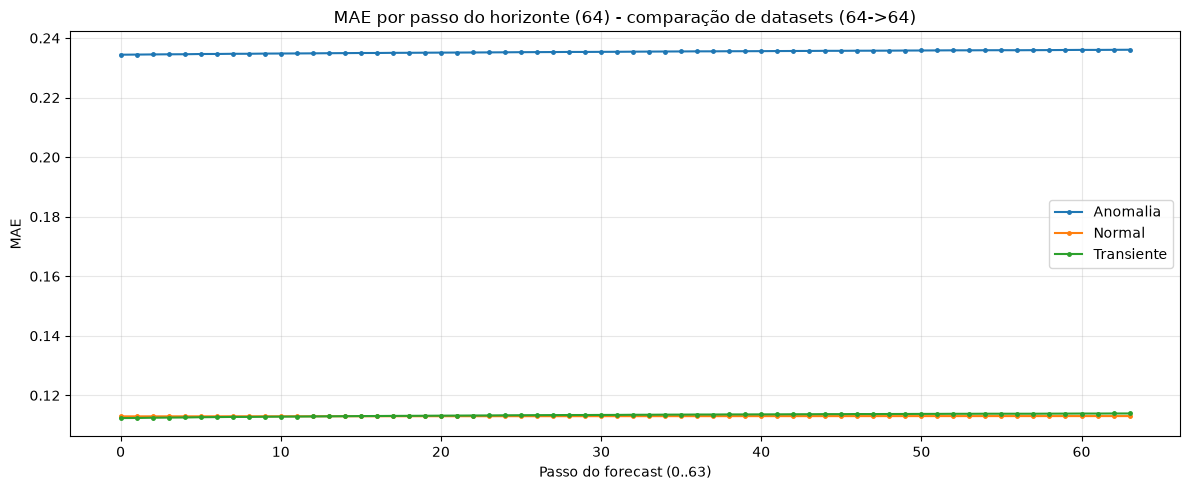

In [11]:
# =========================================================
# Avaliação em lote (DataLoader) 64->64 para 3 datasets
# 1 gráfico com MAE por passo (T=64) para:
# - test_dataset_anomalia
# - test_dataset_normal
# - test_dataset_transiente
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

PAST_LEN = 64
FUTURE_LEN = 64
FORECAST_HORIZON = FUTURE_LEN  # 64

def mae_por_passo_dataset(dataset, dataset_name, batch_size, num_workers=4):
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        drop_last=False,
        num_workers=num_workers,
    )

    model.eval()
    trues = []
    preds = []

    with torch.no_grad():
        for timeseries, forecast, input_mask in loader:
            timeseries = timeseries.float().to(device)   # (B, 64, C)
            forecast   = forecast.float().to(device)     # (B, 64, C)
            input_mask = input_mask.to(device)           # (B, 64)

            timeseries_bct = timeseries.permute(0, 2, 1)   # (B, C, 64)
            target_bct     = ensure_bct(forecast)          # (B, C, 64)

            pred     = get_forecast_prediction(model, timeseries_bct, input_mask)
            pred_bct = ensure_bct(pred)                    # (B, C, 64)

            # pós-processamento (T=64)
            pred_btc   = np.transpose(pred_bct.detach().cpu().numpy(), (0, 2, 1))    # (B, 64, C)
            target_btc = np.transpose(target_bct.detach().cpu().numpy(), (0, 2, 1))  # (B, 64, C)

            pred_btc = postprocess_low_card_numpy(pred_btc)
            pred_btc = quantize_low_card_predictions(pred_btc)

            # opcional, consistente com sua lógica anterior
            target_btc = quantize_low_card_predictions(target_btc)

            # volta para (B, C, 64)
            pred_bct_np   = np.transpose(pred_btc, (0, 2, 1))
            target_bct_np = np.transpose(target_btc, (0, 2, 1))

            preds.append(pred_bct_np)
            trues.append(target_bct_np)

    preds = np.concatenate(preds, axis=0)  # (N, C, 64)
    trues = np.concatenate(trues, axis=0)  # (N, C, 64)

    abs_err = np.abs(preds - trues)
    mae_por_passo = abs_err.mean(axis=(0, 1))  # (64,)

    print(f"[{dataset_name}] preds shape: {preds.shape} | trues shape: {trues.shape}")
    print(f"[{dataset_name}] MAE passo 0: {mae_por_passo[0]}")
    print(f"[{dataset_name}] MAE passo 1: {mae_por_passo[1]}")
    print(f"[{dataset_name}] MAE passo 2: {mae_por_passo[2]}")
    print(f"[{dataset_name}] MAE médio : {mae_por_passo.mean()}")
    print("-" * 60)

    return mae_por_passo


# =========================================================
# Calcula MAE por passo para os 3 datasets
# =========================================================
mae_anomalia   = mae_por_passo_dataset(test_dataset_anomalia,   "Anomalia",   BATCH_SIZE, num_workers=4)
mae_normal     = mae_por_passo_dataset(test_dataset_normal,     "Normal",     BATCH_SIZE, num_workers=4)
mae_transiente = mae_por_passo_dataset(test_dataset_transiente, "Transiente", BATCH_SIZE, num_workers=4)

# =========================================================
# Um único gráfico com as 3 curvas
# =========================================================
plt.figure(figsize=(12, 5))
x = np.arange(FORECAST_HORIZON)

plt.plot(x, mae_anomalia,   marker="o", markersize=2.5, linewidth=1.5, label="Anomalia")
plt.plot(x, mae_normal,     marker="o", markersize=2.5, linewidth=1.5, label="Normal")
plt.plot(x, mae_transiente, marker="o", markersize=2.5, linewidth=1.5, label="Transiente")

plt.title("MAE por passo do horizonte (64) - comparação de datasets (64->64)")
plt.xlabel("Passo do forecast (0..63)")
plt.ylabel("MAE")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


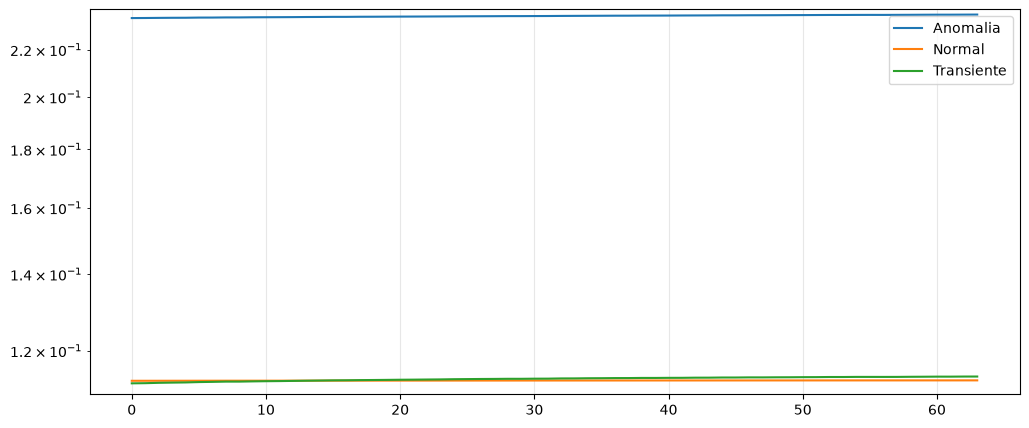

In [ ]:
all_mae = np.concatenate([mae_anomalia, mae_normal, mae_transiente])
ymin, ymax = all_mae.min(), all_mae.max()
margem = 0.02 * (ymax - ymin + 1e-12)  # evita zero

plt.figure(figsize=(12, 5))
x = np.arange(64)
plt.plot(x, mae_anomalia, label="Anomalia")
plt.plot(x, mae_normal, label="Normal")
plt.plot(x, mae_transiente, label="Transiente")
plt.ylim(ymin - margem, ymax + margem)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [24]:
import numpy as np

# escolha de passos (ajuste como quiser)
idx = np.array([0, 1, 2, 4, 8, 16, 32, 63])

def resumo_por_pontos(nome, mae):
    return {
        "dataset": nome,
        **{f"p{int(i)}": float(mae[i]) for i in idx},
        "media_64": float(mae.mean()),
        "min_64": float(mae.min()),
        "max_64": float(mae.max()),
        "delta_p63_p0": float(mae[63] - mae[0]),
    }

linhas = [
    resumo_por_pontos("Anomalia", mae_anomalia),
    resumo_por_pontos("Normal", mae_normal),
    resumo_por_pontos("Transiente", mae_transiente),
]

# imprime como tabela simples (sem pandas)
colunas = ["dataset"] + [f"p{int(i)}" for i in idx] + ["media_64", "min_64", "max_64", "delta_p63_p0"]

# formatação
def fmt(x):
    return f"{x:.6f}" if isinstance(x, float) else str(x)

# header
print(" | ".join(colunas))
print("-" * (len(" | ".join(colunas)) + 10))

for row in linhas:
    print(" | ".join(fmt(row[c]) for c in colunas))


dataset | p0 | p1 | p2 | p4 | p8 | p16 | p32 | p63 | media_64 | min_64 | max_64 | delta_p63_p0
--------------------------------------------------------------------------------------------------------
Anomalia | 0.234401 | 0.234436 | 0.234491 | 0.234553 | 0.234710 | 0.234973 | 0.235416 | 0.236062 | 0.235348 | 0.234401 | 0.236062 | 0.001661
Normal | 0.112941 | 0.112942 | 0.112945 | 0.112950 | 0.112960 | 0.112977 | 0.113005 | 0.113035 | 0.112998 | 0.112941 | 0.113035 | 0.000094
Transiente | 0.112365 | 0.112399 | 0.112479 | 0.112568 | 0.112754 | 0.113058 | 0.113478 | 0.113913 | 0.113356 | 0.112365 | 0.113913 | 0.001548


In [17]:
import torch
import numpy as np
from torch.utils.data import DataLoader

# =========================================================
# Função utilitária: gera preds/trues para um dataset
# =========================================================
def gerar_preds_trues(dataset, model, device, batch_size, num_workers=4):
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        drop_last=False,
        num_workers=num_workers,
    )

    model.eval()
    trues, preds = [], []

    with torch.no_grad():
        for timeseries, forecast, input_mask in loader:
            timeseries = timeseries.float().to(device)        # (B, 64, C)
            forecast = forecast.float().to(device)             # (B, 64, C)
            input_mask = input_mask.to(device)                 # (B, 64)

            timeseries_bct = timeseries.permute(0, 2, 1)        # (B, C, 64)
            target_bct = ensure_bct(forecast)                   # (B, C, 64)

            pred = get_forecast_prediction(model, timeseries_bct, input_mask)
            pred_bct = ensure_bct(pred)                          # (B, C, 64)

            pred_btc = np.transpose(pred_bct.detach().cpu().numpy(), (0, 2, 1))
            target_btc = np.transpose(target_bct.detach().cpu().numpy(), (0, 2, 1))

            pred_btc = postprocess_low_card_numpy(pred_btc)
            pred_btc = quantize_low_card_predictions(pred_btc)
            target_btc = quantize_low_card_predictions(target_btc)

            pred_bct_np = np.transpose(pred_btc, (0, 2, 1))
            target_bct_np = np.transpose(target_btc, (0, 2, 1))

            preds.append(pred_bct_np)
            trues.append(target_bct_np)

    preds = np.concatenate(preds, axis=0)   # (N, C, 64)
    trues = np.concatenate(trues, axis=0)   # (N, C, 64)
    return preds, trues


# =========================================================
# Função: quantos desvios padrão cada ponto fica do real
# =========================================================
def n_desvios_padrao(preds, trues, media_erro=None, std_erro=None,
                      eixo_std=(0, 2), eps=1e-8):
    """
    erro = preds - trues
    n_desvios = (erro - media_erro) / std_erro

    Se media_erro/std_erro não forem informados, são calculados
    a partir do próprio preds/trues recebido (normalização interna).
    Para usar as estatísticas do baseline 'normal' em outro dataset,
    passe media_erro e std_erro vindos do dataset normal.

    eixo_std=(0, 2) -> desvio por canal C (usa todas amostras N e todo horizonte T)
    eixo_std=None   -> um único desvio padrão global
    """
    erro = preds - trues

    if media_erro is None:
        media_erro = erro.mean(axis=eixo_std, keepdims=True) if eixo_std is not None else erro.mean()
    if std_erro is None:
        std_erro = erro.std(axis=eixo_std, keepdims=True) if eixo_std is not None else erro.std()

    std_erro = np.where(std_erro < eps, eps, std_erro)
    n_desvios = (erro - media_erro) / std_erro
    return erro, n_desvios, media_erro, std_erro


# =========================================================
# Pipeline completo para os 3 datasets
# =========================================================
BATCH_SIZE = BATCH_SIZE  # já definido no seu notebook
device = device          # já definido no seu notebook

# 1) Baseline (normal) -> define média/desvio de referência
preds_normal, trues_normal = gerar_preds_trues(test_dataset_normal, model, device, BATCH_SIZE)
erro_normal, zscore_normal, media_erro_base, std_erro_base = n_desvios_padrao(
    preds_normal, trues_normal, eixo_std=(0, 2)
)

# 2) Transiente -> usa as estatísticas do baseline
preds_transiente, trues_transiente = gerar_preds_trues(test_dataset_transiente, model, device, BATCH_SIZE)
erro_transiente, zscore_transiente, _, _ = n_desvios_padrao(
    preds_transiente, trues_transiente,
    media_erro=media_erro_base, std_erro=std_erro_base
)

# 3) Anomalia -> usa as estatísticas do baseline
preds_anomalia, trues_anomalia = gerar_preds_trues(test_dataset_anomalia, model, device, BATCH_SIZE)
erro_anomalia, zscore_anomalia, _, _ = n_desvios_padrao(
    preds_anomalia, trues_anomalia,
    media_erro=media_erro_base, std_erro=std_erro_base
)

# =========================================================
# Resumo
# =========================================================
resultados = {
    "normal":     {"n_desvios": zscore_normal},
    "transiente": {"n_desvios": zscore_transiente},
    "anomalia":   {"n_desvios": zscore_anomalia},
}

for nome, r in resultados.items():
    nd = np.abs(r["n_desvios"])
    print(f"[{nome}] média |n_desvios|: {nd.mean():.3f} | p95: {np.percentile(nd, 95):.3f} | máx: {nd.max():.3f}")


[normal] média |n_desvios|: 0.413 | p95: 1.782 | máx: 355.585
[transiente] média |n_desvios|: 61.642 | p95: 8.111 | máx: 635768.562
[anomalia] média |n_desvios|: 62.004 | p95: 354.889 | máx: 175202.609


In [19]:
import numpy as np

# 1) Identificar quais canais têm std_erro suspeito (perto do eps)
eps = 1e-8
std_flat = std_erro_base.squeeze()  # (C,)
canais_suspeitos = np.where(std_flat < 1e-4)[0]
print("Canais com std quase zero no baseline normal:", canais_suspeitos)
print("Valores de std nesses canais:", std_flat[canais_suspeitos])

# 2) Localizar onde está o z-score máximo no transiente
idx_max = np.unravel_index(np.argmax(np.abs(zscore_transiente)), zscore_transiente.shape)
print("Posição do z máximo (N, C, T):", idx_max)
print("Canal responsável:", idx_max[1], "| erro bruto nesse ponto:", erro_transiente[idx_max])
print("std_erro desse canal:", std_erro_base[0, idx_max[1], 0])

# 3) Métrica robusta alternativa: mediana e MAD em vez de média/desvio
mediana_erro = np.median(erro_normal, axis=(0, 2), keepdims=True)
mad_erro = np.median(np.abs(erro_normal - mediana_erro), axis=(0, 2), keepdims=True)
mad_erro = np.where(mad_erro < eps, eps, mad_erro)
# fator 1.4826 torna o MAD comparável a um desvio padrão sob normalidade
zscore_robusto_transiente = (erro_transiente - mediana_erro) / (1.4826 * mad_erro)


Canais com std quase zero no baseline normal: [10]
Valores de std nesses canais: [8.955467e-06]
Posição do z máximo (N, C, T): (np.int64(41965), np.int64(10), np.int64(5))
Canal responsável: 10 | erro bruto nesse ponto: 5.693606
std_erro desse canal: 8.955467e-06


In [20]:
import numpy as np
import pandas as pd

# =========================================================
# Função: estatísticas robustas por canal (variável)
# =========================================================
def analisar_variaveis(preds, trues, nome_dataset,
                        media_erro_base=None, std_erro_base=None,
                        mediana_erro_base=None, mad_erro_base=None,
                        eps=1e-8, limiar_degenerado=0.01):
    """
    preds, trues: arrays (N, C, T)
    *_base: estatísticas de referência (ex: calculadas no dataset 'normal').
            Se None, são calculadas a partir do próprio preds/trues.
    limiar_degenerado: canais cujo std_erro_base é menor que
            (limiar_degenerado * mediana dos std_erro_base de todos os canais)
            são marcados como degenerados (quase constantes / baixa cardinalidade).

    Retorna um DataFrame com uma linha por canal.
    """
    N, C, T = preds.shape
    erro = preds - trues  # (N, C, T)

    # ---- estatísticas clássicas (média/desvio) por canal ----
    media_erro = erro.mean(axis=(0, 2))                     # (C,)
    std_erro   = erro.std(axis=(0, 2))                       # (C,)

    # ---- estatísticas robustas (mediana/MAD) por canal ----
    mediana = np.median(erro, axis=(0, 2))                   # (C,)
    mad = np.median(np.abs(erro - mediana.reshape(1, C, 1)), axis=(0, 2))  # (C,)

    # ---- se não informado, usa as próprias estatísticas como baseline ----
    if media_erro_base is None:
        media_erro_base = media_erro
    else:
        media_erro_base = np.asarray(media_erro_base).reshape(C)
    if std_erro_base is None:
        std_erro_base = std_erro
    else:
        std_erro_base = np.asarray(std_erro_base).reshape(C)
    if mediana_erro_base is None:
        mediana_erro_base = mediana
    else:
        mediana_erro_base = np.asarray(mediana_erro_base).reshape(C)
    if mad_erro_base is None:
        mad_erro_base = mad
    else:
        mad_erro_base = np.asarray(mad_erro_base).reshape(C)

    std_erro_safe = np.where(std_erro_base < eps, eps, std_erro_base)
    mad_erro_safe = np.where(mad_erro_base < eps, eps, mad_erro_base)

    # ---- detecção de canais degenerados (variância quase nula no baseline) ----
    mediana_std_global = np.median(std_erro_base[std_erro_base > eps]) if np.any(std_erro_base > eps) else eps
    canal_degenerado = std_erro_base < (limiar_degenerado * mediana_std_global)

    # ---- z-score clássico e robusto, por canal ----
    z_classico = (erro - media_erro_base.reshape(1, C, 1)) / std_erro_safe.reshape(1, C, 1)
    z_robusto  = (erro - mediana_erro_base.reshape(1, C, 1)) / (1.4826 * mad_erro_safe.reshape(1, C, 1))

    linhas = []
    for c in range(C):
        erro_c = erro[:, c, :]
        pred_c = preds[:, c, :].ravel()
        true_c = trues[:, c, :].ravel()
        z_c  = z_classico[:, c, :]
        zr_c = z_robusto[:, c, :]

        # erro absoluto e quadrático
        mae  = np.abs(erro_c).mean()
        rmse = np.sqrt((erro_c ** 2).mean())

        # correlação de Pearson entre previsto e real
        if true_c.std() > eps and pred_c.std() > eps:
            corr = np.corrcoef(pred_c, true_c)[0, 1]
        else:
            corr = np.nan

        # R² (coeficiente de determinação)
        ss_res = np.sum((true_c - pred_c) ** 2)
        ss_tot = np.sum((true_c - true_c.mean()) ** 2)
        r2 = 1 - ss_res / ss_tot if ss_tot > eps else np.nan

        # assimetria e curtose (sem scipy)
        erro_flat = erro_c.ravel()
        s = erro_flat.std()
        if s > eps:
            skew = np.mean(((erro_flat - erro_flat.mean()) / s) ** 3)
            kurt = np.mean(((erro_flat - erro_flat.mean()) / s) ** 4) - 3
        else:
            skew, kurt = np.nan, np.nan

        total_pontos = erro_c.size

        linhas.append({
            "dataset": nome_dataset,
            "canal": c,
            "degenerado": bool(canal_degenerado[c]),
            "erro_medio": media_erro[c],
            "erro_std": std_erro[c],
            "erro_mediana": mediana[c],
            "erro_mad": mad[c],
            "mae": mae,
            "rmse": rmse,
            "corr_pred_real": corr,
            "r2": r2,
            "skewness": skew,
            "kurtosis": kurt,
            "z_classico_media_abs": np.abs(z_c).mean(),
            "z_classico_p95_abs": np.percentile(np.abs(z_c), 95),
            "z_classico_max_abs": np.abs(z_c).max(),
            "pct_fora_1sigma_classico": 100 * (np.abs(z_c) > 1).sum() / total_pontos,
            "pct_fora_2sigma_classico": 100 * (np.abs(z_c) > 2).sum() / total_pontos,
            "pct_fora_3sigma_classico": 100 * (np.abs(z_c) > 3).sum() / total_pontos,
            "z_robusto_media_abs": np.abs(zr_c).mean(),
            "z_robusto_p95_abs": np.percentile(np.abs(zr_c), 95),
            "z_robusto_max_abs": np.abs(zr_c).max(),
            "pct_fora_1sigma_robusto": 100 * (np.abs(zr_c) > 1).sum() / total_pontos,
            "pct_fora_2sigma_robusto": 100 * (np.abs(zr_c) > 2).sum() / total_pontos,
            "pct_fora_3sigma_robusto": 100 * (np.abs(zr_c) > 3).sum() / total_pontos,
        })

    df = pd.DataFrame(linhas)
    return df


# =========================================================
# Aplicando para os 3 datasets, usando o 'normal' como baseline
# (reaproveitando preds_*, trues_*, media_erro_base, std_erro_base,
#  mediana_erro, mad_erro já calculados nas etapas anteriores)
# =========================================================

# estatísticas de baseline em formato (C,) -- squeeze dos keepdims anteriores
media_base_c   = media_erro_base.squeeze()
std_base_c     = std_erro_base.squeeze()
mediana_base_c = mediana_erro.squeeze()
mad_base_c     = mad_erro.squeeze()

df_normal = analisar_variaveis(
    preds_normal, trues_normal, "normal",
    media_erro_base=media_base_c, std_erro_base=std_base_c,
    mediana_erro_base=mediana_base_c, mad_erro_base=mad_base_c
)

df_transiente = analisar_variaveis(
    preds_transiente, trues_transiente, "transiente",
    media_erro_base=media_base_c, std_erro_base=std_base_c,
    mediana_erro_base=mediana_base_c, mad_erro_base=mad_base_c
)

df_anomalia = analisar_variaveis(
    preds_anomalia, trues_anomalia, "anomalia",
    media_erro_base=media_base_c, std_erro_base=std_base_c,
    mediana_erro_base=mediana_base_c, mad_erro_base=mad_base_c
)

df_todos = pd.concat([df_normal, df_transiente, df_anomalia], ignore_index=True)

# =========================================================
# Exibição: canais degenerados primeiro (alerta), depois ranking
# =========================================================
print("Canais degenerados detectados (baixa variância no baseline normal):")
print(df_normal.loc[df_normal["degenerado"], ["canal", "erro_std"]])

print("\nTop 10 canais com maior % de pontos fora de 2 sigma (robusto) no transiente:")
print(
    df_transiente.sort_values("pct_fora_2sigma_robusto", ascending=False)
    .head(10)[["canal", "degenerado", "mae", "rmse", "corr_pred_real", "r2",
               "pct_fora_2sigma_robusto"]]
)

print("\nTop 10 canais com maior % de pontos fora de 2 sigma (robusto) na anomalia:")
print(
    df_anomalia.sort_values("pct_fora_2sigma_robusto", ascending=False)
    .head(10)[["canal", "degenerado", "mae", "rmse", "corr_pred_real", "r2",
               "pct_fora_2sigma_robusto"]]
)

# df_todos fica disponível para exportar / plotar / inspecionar livremente


/home/victor.franco/.local/.3W-unsupervised-learning/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/victor.franco/.local/.3W-unsupervised-learning/lib64/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Canais degenerados detectados (baixa variância no baseline normal):
    canal  erro_std
10     10  0.000009

Top 10 canais com maior % de pontos fora de 2 sigma (robusto) no transiente:
    canal  degenerado       mae      rmse  corr_pred_real        r2  \
8       8       False  0.001969  0.004204        0.937550  0.838954   
6       6       False  0.746775  0.762712             NaN -7.217428   
1       1       False  0.111107  0.259221             NaN -0.023873   
11     11       False  0.001756  0.012551        0.999921  0.999842   
5       5       False  0.132228  0.239112             NaN -0.022332   
12     12       False  0.003936  0.025888        0.999666  0.999331   
13     13       False  0.000515  0.007694        0.999970  0.999941   
9       9       False  0.011084  0.039786        0.999215  0.998417   
10     10        True  0.007550  0.072530        0.997371  0.994736   
7       7       False  0.256309  0.294872        0.002228 -0.907875   

    pct_fora_2sigma_robusto  
8 

In [22]:
import numpy as np
import pandas as pd

# =========================================================
# Reaproveita df_todos (normal + transiente + anomalia) já gerado
# e pivota para formato wide: 1 linha por canal, colunas = métrica_dataset
# =========================================================

metricas_interesse = [
    "erro_medio", "erro_mediana", "mae", "rmse",
    "corr_pred_real", "r2",
    "z_robusto_media_abs", "z_robusto_p95_abs", "z_robusto_max_abs",
    "pct_fora_1sigma_robusto", "pct_fora_2sigma_robusto", "pct_fora_3sigma_robusto",
]

# flag de canal degenerado vem só do baseline normal (é a referência)
flag_degenerado = (
    df_normal[["canal", "degenerado"]]
    .rename(columns={"degenerado": "degenerado_no_normal"})
)

# pivota: index=canal, columns=dataset, values=cada métrica
tabela_comparativa = df_todos.pivot(index="canal", columns="dataset", values=metricas_interesse)

# reordena colunas: para cada métrica, mostrar normal | transiente | anomalia
ordem_datasets = ["normal", "transiente", "anomalia"]
tabela_comparativa = tabela_comparativa.reindex(columns=ordem_datasets, level=1)

# "achata" o MultiIndex de colunas em algo tipo "mae_normal", "mae_transiente", ...
tabela_comparativa.columns = [f"{metrica}_{dataset}" for metrica, dataset in tabela_comparativa.columns]
tabela_comparativa = tabela_comparativa.reset_index()

# junta a flag de canal degenerado (baseado no baseline normal)
tabela_comparativa = tabela_comparativa.merge(flag_degenerado, on="canal", how="left")

# reordena colunas: canal, flag, depois cada métrica agrupada
colunas_ordenadas = ["canal", "degenerado_no_normal"]
for metrica in metricas_interesse:
    for ds in ordem_datasets:
        colunas_ordenadas.append(f"{metrica}_{ds}")
tabela_comparativa = tabela_comparativa[colunas_ordenadas]

# =========================================================
# Exibição
# =========================================================
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("Tabela comparativa por canal (normal vs transiente vs anomalia):")
print(tabela_comparativa.round(4))

# Ordenar pelo indicador mais relevante para detecção de anomalia:
# diferença no % de pontos fora de 2 sigma (robusto) entre anomalia e normal
tabela_comparativa["delta_pct_2sigma_anomalia_vs_normal"] = (
    tabela_comparativa["pct_fora_2sigma_robusto_anomalia"]
    - tabela_comparativa["pct_fora_2sigma_robusto_normal"]
)

# tabela_comparativa fica disponível para exportar, plotar ou inspecionar


Tabela comparativa por canal (normal vs transiente vs anomalia):
    canal  degenerado_no_normal  erro_medio_normal  erro_medio_transiente  erro_medio_anomalia  erro_mediana_normal  erro_mediana_transiente  erro_mediana_anomalia  mae_normal  mae_transiente  \
0       0                 False             0.1159                -0.0000               0.0018               0.0000                   0.0000                 0.0000      0.1926          0.0699   
1       1                 False            -0.2155                 0.0389              -0.2290              -0.2059                   0.0000                -0.2059      0.2074          0.1111   
2       2                 False             0.0983                 0.1517               0.4954               0.1075                   0.1075                 0.5000      0.2850          0.2107   
3       3                 False             0.0040                 0.0021               0.9604               0.0000                   0.0000               

In [26]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# =========================================================
# 1) Função: constrói features por amostra a partir do erro
#    (reaproveita preds_*, trues_*, media_erro_base, std_erro_base
#    já calculados nas etapas anteriores)
# =========================================================
def construir_features(preds, trues, media_erro_base, std_erro_base, eps=1e-8):
    """
    preds, trues: (N, C, T)
    media_erro_base, std_erro_base: (C,) -- estatísticas do baseline 'normal'

    Retorna um DataFrame (N linhas) com features agregadas por amostra:
    - estatísticas globais do erro (todas as C, T)
    - estatísticas do z-score robusto por amostra
    - estatísticas por canal resumidas em poucos agregados (média/máx entre canais)
    """
    N, C, T = preds.shape
    erro = preds - trues  # (N, C, T)

    std_safe = np.where(std_erro_base < eps, eps, std_erro_base).reshape(1, C, 1)
    media_b = media_erro_base.reshape(1, C, 1)
    z = (erro - media_b) / std_safe  # (N, C, T), z-score usando baseline normal

    # ---- agregados globais por amostra (sobre C e T juntos) ----
    erro_flat = erro.reshape(N, -1)
    z_flat = z.reshape(N, -1)

    feats = pd.DataFrame({
        "erro_media": erro_flat.mean(axis=1),
        "erro_std": erro_flat.std(axis=1),
        "erro_abs_media": np.abs(erro_flat).mean(axis=1),
        "erro_abs_max": np.abs(erro_flat).max(axis=1),
        "erro_abs_p95": np.percentile(np.abs(erro_flat), 95, axis=1),
        "z_abs_media": np.abs(z_flat).mean(axis=1),
        "z_abs_max": np.abs(z_flat).max(axis=1),
        "z_abs_p95": np.percentile(np.abs(z_flat), 95, axis=1),
        "pct_fora_1sigma": (np.abs(z_flat) > 1).mean(axis=1) * 100,
        "pct_fora_2sigma": (np.abs(z_flat) > 2).mean(axis=1) * 100,
        "pct_fora_3sigma": (np.abs(z_flat) > 3).mean(axis=1) * 100,
    })

    # ---- agregados por canal, resumidos (média e máximo entre os C canais) ----
    erro_abs_medio_por_canal = np.abs(erro).mean(axis=2)   # (N, C)
    z_abs_medio_por_canal = np.abs(z).mean(axis=2)          # (N, C)

    feats["canal_erro_abs_media_media"] = erro_abs_medio_por_canal.mean(axis=1)
    feats["canal_erro_abs_media_max"]   = erro_abs_medio_por_canal.max(axis=1)
    feats["canal_z_abs_media_media"]    = z_abs_medio_por_canal.mean(axis=1)
    feats["canal_z_abs_media_max"]      = z_abs_medio_por_canal.max(axis=1)

    return feats


# =========================================================
# 2) Monta o dataset rotulado (normal=0, transiente=1, anomalia=2)
# =========================================================
feats_normal = construir_features(preds_normal, trues_normal, media_base_c, std_base_c)
feats_normal["rotulo"] = 0
feats_normal["rotulo_nome"] = "normal"

feats_transiente = construir_features(preds_transiente, trues_transiente, media_base_c, std_base_c)
feats_transiente["rotulo"] = 1
feats_transiente["rotulo_nome"] = "transiente"

feats_anomalia = construir_features(preds_anomalia, trues_anomalia, media_base_c, std_base_c)
feats_anomalia["rotulo"] = 2
feats_anomalia["rotulo_nome"] = "anomalia"

df_dataset = pd.concat([feats_normal, feats_transiente, feats_anomalia], ignore_index=True)

colunas_features = [c for c in df_dataset.columns if c not in ("rotulo", "rotulo_nome")]
X = df_dataset[colunas_features].values
y = df_dataset["rotulo"].values

print("Shape final do dataset de features:", X.shape)
print("Distribuição das classes:\n", df_dataset["rotulo_nome"].value_counts())

# =========================================================
# 3) Split treino/teste estratificado
# =========================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# padronização (importante para LogisticRegression; não essencial p/ RandomForest, mas não prejudica)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =========================================================
# 4) Treina o modelo simples (Random Forest) + baseline (Regressão Logística)
# =========================================================
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)  # árvores não exigem padronização

logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(X_train_scaled, y_train)

# =========================================================
# 5) Avaliação
# =========================================================
nomes_classes = ["normal", "transiente", "anomalia"]

for nome_modelo, modelo, X_test_usado in [
    ("Random Forest", rf, X_test),
    ("Regressão Logística", logreg, X_test_scaled),
]:
    y_pred = modelo.predict(X_test_usado)
    acc = accuracy_score(y_test, y_pred)
    print(f"\n=== {nome_modelo} ===")
    print(f"Acurácia: {acc:.4f}")
    print("Matriz de confusão (linhas=real, colunas=previsto):")
    print(pd.DataFrame(
        confusion_matrix(y_test, y_pred),
        index=[f"real_{c}" for c in nomes_classes],
        columns=[f"prev_{c}" for c in nomes_classes],
    ))
    print("Relatório de classificação:")
    print(classification_report(y_test, y_pred, target_names=nomes_classes))

# =========================================================
# 6) Importância das features (Random Forest) -- ajuda a entender
#    quais estatísticas de erro mais discriminam os 3 estados
# =========================================================
importancias = pd.DataFrame({
    "feature": colunas_features,
    "importancia": rf.feature_importances_
}).sort_values("importancia", ascending=False)

print("\nImportância das features (Random Forest):")
print(importancias)


Shape final do dataset de features: (568876, 15)
Distribuição das classes:
 rotulo_nome
anomalia      227860
transiente    205040
normal        135976
Name: count, dtype: int64

=== Random Forest ===
Acurácia: 0.9910
Matriz de confusão (linhas=real, colunas=previsto):
                 prev_normal  prev_transiente  prev_anomalia
real_normal            40612              170             11
real_transiente          737            60712             63
real_anomalia            368              185          67805
Relatório de classificação:
              precision    recall  f1-score   support

      normal       0.97      1.00      0.98     40793
  transiente       0.99      0.99      0.99     61512
    anomalia       1.00      0.99      1.00     68358

    accuracy                           0.99    170663
   macro avg       0.99      0.99      0.99    170663
weighted avg       0.99      0.99      0.99    170663


=== Regressão Logística ===
Acurácia: 0.9718
Matriz de confusão (linhas=real,

In [27]:
import numpy as np
import plotly.graph_objects as go
from sklearn.metrics import confusion_matrix

nomes_classes = ["normal", "transiente", "anomalia"]

def montar_annot(cm):
    """Monta texto de cada célula: valor absoluto + percentual por linha (classe real)."""
    total_linha = cm.sum(axis=1, keepdims=True)
    pct = cm / total_linha * 100
    texto = [[f"{cm[i][j]}<br>({pct[i][j]:.1f}%)" for j in range(cm.shape[1])] for i in range(cm.shape[0])]
    return texto

def plot_matriz_confusao(y_test, y_pred_rf, y_pred_logreg, acc_rf, acc_logreg):
    cm_rf = confusion_matrix(y_test, y_pred_rf)
    cm_logreg = confusion_matrix(y_test, y_pred_logreg)

    fig = go.Figure()

    # Heatmap 1 - Random Forest (lado esquerdo)
    fig.add_trace(go.Heatmap(
        z=cm_rf,
        x=[f"prev_{c}" for c in nomes_classes],
        y=[f"real_{c}" for c in nomes_classes],
        text=montar_annot(cm_rf),
        texttemplate="%{text}",
        textfont={"size": 13},
        colorscale="Blues",
        showscale=False,
        xaxis="x1",
        yaxis="y1",
    ))

    # Heatmap 2 - Regressão Logística (lado direito)
    fig.add_trace(go.Heatmap(
        z=cm_logreg,
        x=[f"prev_{c}" for c in nomes_classes],
        y=[f"real_{c}" for c in nomes_classes],
        text=montar_annot(cm_logreg),
        texttemplate="%{text}",
        textfont={"size": 13},
        colorscale="Oranges",
        showscale=False,
        xaxis="x2",
        yaxis="y2",
    ))

    fig.update_layout(
        title_text=(
            "Matriz de Confusão: Random Forest vs Regressão Logística"
            "<br><sup>Classificação de registros em normal / transiente / anomalia</sup>"
        ),
        height=500,
        width=1050,
        xaxis=dict(domain=[0.0, 0.42], title=f"Random Forest (acc={acc_rf:.2%})", anchor="y1"),
        yaxis=dict(domain=[0.0, 1.0], autorange="reversed", anchor="x1"),
        xaxis2=dict(domain=[0.58, 1.0], title=f"Regressão Logística (acc={acc_logreg:.2%})", anchor="y2"),
        yaxis2=dict(domain=[0.0, 1.0], autorange="reversed", anchor="x2"),
    )

    fig.show()
    return fig


# =========================================================
# Uso com as variáveis já existentes no seu notebook
# (y_test, e as previsões de cada modelo da etapa anterior)
# =========================================================
y_pred_rf = rf.predict(X_test)
y_pred_logreg = logreg.predict(X_test_scaled)

acc_rf = accuracy_score(y_test, y_pred_rf)
acc_logreg = accuracy_score(y_test, y_pred_logreg)

fig = plot_matriz_confusao(y_test, y_pred_rf, y_pred_logreg, acc_rf, acc_logreg)
